In [2]:
# Import necessary libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

gender                                    female
race/ethnicity                           group B
parental level of education    bachelor's degree
lunch                                   standard
test preparation course                     none
math score                                    72
reading score                                 72
writing score                                 74
Name: 0, dtype: object

gender                               female
race/ethnicity                      group C
parental level of education    some college
lunch                              standard
test preparation course           completed
math score                               69
reading score                            90
writing score                            88
Name: 1, dtype: object

gender                                  female
race/ethnicity                         group B
parental level of education    master's degree
lunch                                 standard
test preparation cou

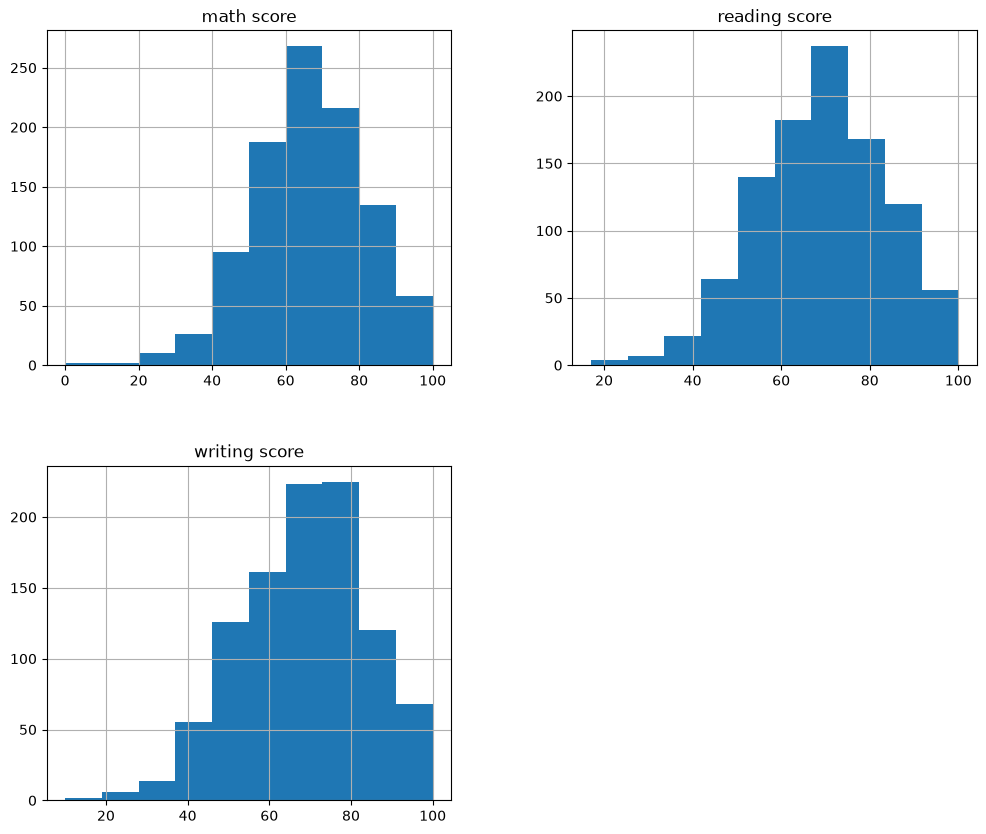

gender
str

race/ethnicity
str

parental level of education
str

lunch
str

test preparation course
str

math score
int64

reading score
int64

writing score
int64

Numeric columns: Index(['math score', 'reading score', 'writing score'], dtype='str')
Categorical columns: Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course'],
      dtype='str')


/tmp/ipykernel_12292/3027112974.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = dataset.select_dtypes(include=['object']).columns


In [3]:
#Q2A

# Load and display the first 10 rows of the student performance dataset
dataset = pd.read_csv('datasets/Q2_Student_Performance_Dataset.csv')
for i in range(0,10):
    print(f'{dataset.iloc[i,:]}\n')

# graph dataset distrubtion
dataset.hist(figsize=(12,10))
plt.show()

# Display the column names of the dataset
for i in range(len(dataset.columns)):
    print(f'{dataset.columns[i]}\n{dataset[dataset.columns[i]].dtype}\n')

# Identify numeric and categorical columns in the dataset
numeric_columns = dataset.select_dtypes(include=['number']).columns
categorical_columns = dataset.select_dtypes(include=['object']).columns
print(f'Numeric columns: {numeric_columns}')
print(f'Categorical columns: {categorical_columns}')


In [4]:
#Q2B

# Check for missing values in the dataset
if dataset.iloc[:].isnull().any().any():
    print("There are missing values in the dataset.")
else:
    print("There are no missing values in the dataset.")

# Check for duplicate rows in the dataset
if dataset.iloc[:].duplicated().any():
    print("There are duplicate rows in the dataset.")
else:
    print("There are no duplicate rows in the dataset.")

# checking for inconsistent values in the categorical columns
column_values = {col: dataset[col].unique() for col in dataset.columns}
for col, values in column_values.items():
    print(f"Column {col} has values: {values}")

print("Finished checking for inconsistent values in the categorical columns.\n"
      "No inconsistent values found.")

for i in range(len(categorical_columns)):
    print(f'{categorical_columns[i]} has values: {column_values[categorical_columns[i]]}'
          f' with datatype: {dataset[categorical_columns[i]].dtype}')

math_scores = dataset['math score'].tolist()
reading_scores = dataset['reading score'].tolist()
writing_scores = dataset['writing score'].tolist()

math_iqr = np.percentile(math_scores, 75) - np.percentile(math_scores, 25)
reading_iqr = np.percentile(reading_scores, 75) - np.percentile(reading_scores, 25)
writing_iqr = np.percentile(writing_scores, 75) - np.percentile(writing_scores, 25)

# Identifying outliers in each score column using the IQR method
math_outliers = []
for i in range(len(math_scores)):
    if (math_scores[i] < (np.percentile(math_scores, 25) - 1.5 * math_iqr)) or (math_scores[i] > (np.percentile(math_scores, 75) + 1.5 * math_iqr)):
        math_outliers.append(math_scores[i])
reading_outliers = []
for i in range(len(reading_scores)):
    if (reading_scores[i] < (np.percentile(reading_scores, 25) - 1.5 * reading_iqr)) or (reading_scores[i] > (np.percentile(reading_scores, 75) + 1.5 * reading_iqr)):
        reading_outliers.append(reading_scores[i])
writing_outliers = []
for i in range(len(writing_scores)):
    if (writing_scores[i] < (np.percentile(writing_scores, 25) - 1.5 * writing_iqr)) or (writing_scores[i] > (np.percentile(writing_scores, 75) + 1.5 * writing_iqr)):
        writing_outliers.append(writing_scores[i])
print(f'Math outliers: {math_outliers}')
print(f'Reading outliers: {reading_outliers}')
print(f'Writing outliers: {writing_outliers}')

# Removing rows with outliers in at least two of the score columns
removed_columns = 0
for i in range(0, len(dataset) - 1):
    if ((dataset.iloc[i, 5] in math_outliers and dataset.iloc[i, 5] in reading_outliers) or
       (dataset.iloc[i, 5] in math_outliers and dataset.iloc[i, 5] in writing_outliers) or
       (dataset.iloc[i, 5] in reading_outliers and dataset.iloc[i, 5] in writing_outliers)):
        
        dataset.drop(dataset.index[i], inplace=True)
        removed_columns += 1
        i -= 1

print(f'Total removed rows: {removed_columns} because they had 2 or more outliers in the scores columns.')



There are no missing values in the dataset.
There are no duplicate rows in the dataset.
Column gender has values: <StringArray>
['female', 'male']
Length: 2, dtype: str
Column race/ethnicity has values: <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Column parental level of education has values: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Column lunch has values: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Column test preparation course has values: <StringArray>
['none', 'completed']
Length: 2, dtype: str
Column math score has values: [ 72  69  90  47  76  71  88  40  64  38  58  65  78  50  18  46  54  66
  44  74  73  67  70  62  63  56  97  81  75  57  55  53  59  82  77  33
  52   0  79  39  45  60  61  41  49  30  80  42  27  43  68  85  98  87
  51  99  84  91  83  89  22 100  96  94  48  35

IndexError: index 995 is out of bounds for axis 0 with size 995

In [ ]:
# Q2C

# calculating summary statistics for the scores columns
math_summary = dataset['math score'].describe()
reading_summary = dataset['reading score'].describe()
writing_summary = dataset['writing score'].describe()

print("Math Summary Statistics:\n", math_summary)
print("Reading Summary Statistics:\n", reading_summary)
print("Writing Summary Statistics:\n", writing_summary)

print('Reading mean is better than Writing mean, which is better than Math mean.')

math_no_prep = dataset[dataset['test preparation course'] == 'none']['math score'].describe()
reading_no_prep = dataset[dataset['test preparation course'] == 'none']['reading score'].describe()
writing_no_prep = dataset[dataset['test preparation course'] == 'none']['writing score'].describe()
math_prep = dataset[dataset['test preparation course'] == 'completed']['math score'].describe()
reading_prep = dataset[dataset['test preparation course'] == 'completed']['reading score'].describe()
writing_prep = dataset[dataset['test preparation course'] == 'completed']['writing score'].describe()
if math_prep['mean'] > math_no_prep['mean']:
    print("Math scores improved after test preparation.")
else:
    print("Math scores did not improve after test preparation.")

if reading_prep['mean'] > reading_no_prep['mean']:
    print("Reading scores improved after test preparation.")
else:
    print("Reading scores did not improve after test preparation.")

if writing_prep['mean'] > writing_no_prep['mean']:
    print("Writing scores improved after test preparation.")
else:
    print("Writing scores did not improve after test preparation.")



Math Summary Statistics:
 count    995.000000
mean      66.306533
std       14.885394
min        0.000000
25%       57.000000
50%       66.000000
75%       77.000000
max      100.000000
Name: math score, dtype: float64
Reading Summary Statistics:
 count    995.000000
mean      69.325628
std       14.465128
min       17.000000
25%       59.500000
50%       70.000000
75%       79.500000
max      100.000000
Name: reading score, dtype: float64
Writing Summary Statistics:
 count    995.000000
mean      68.229146
std       15.028536
min       10.000000
25%       58.000000
50%       69.000000
75%       79.000000
max      100.000000
Name: writing score, dtype: float64
Reading mean is better than Writing mean, which is better than Math mean.
Math scores improved after test preparation.
73.97759103641457
66.72257053291536
Reading scores improved after test preparation.
Writing scores improved after test preparation.
